# Filter Median (Non-Linear Filter)

---

### 1. Konsep Dasar Filter Median

Filter median adalah filter non-linear yang digunakan untuk mereduksi derau, terutama jenis *salt-and-pepper noise* (derau impulsif). Berbeda dengan filter spasial linier yang menghitung rata-rata tertimbang melalui konvolusi, filter median menggantikan nilai piksel sentral dengan nilai median statistik dari jendela ketetanggaannya.

**Langkah Kerja:**
1. Tentukan jendela lokal berukuran ganjil ($3 \times 3$, $5 \times 5$, dst.).
2. Ekstrak seluruh intensitas piksel di dalam jendela tersebut.
3. Urutkan seluruh nilai intensitas secara terurut (*ascending*).
4. Ambil nilai tengah (median) dan tetapkan sebagai nilai baru untuk piksel pusat.

**Karakteristik Utama:**
- **Robust terhadap Outlier:** Nilai ekstrem (0 atau 255) tereliminasi secara statistik saat pengurutan.
- **Preservasi Tepi (*Edge Preservation*):** Menjaga ketajaman garis kontur objek jauh lebih baik dibandingkan filter perataan linier (*mean filter*).

### 2. Ilustrasi Numerik

Diberikan matriks ketetanggaan $3 \times 3$ dengan satu piksel derau impulsif bernilai 255 di pusat:

$$
\begin{bmatrix}
12 & 10 & 102 \\
8 & \mathbf{255} & 9 \\
13 & 11 & 14
\end{bmatrix}
$$

- **Daftar terurut:** $[8, 9, 10, 11, \mathbf{12}, 13, 14, 102, 255]$
- **Nilai Median (elemen ke-5):** **12**
- Nilai piksel sentral yang semula **255** digantikan sepenuhnya oleh **12**.

### 3. Implementasi Python

#### a. Persiapan Data Citra
Kode berikut menginisialisasi pustaka serta menyediakan gambar uji secara otomatis jika file lokal belum tersedia.

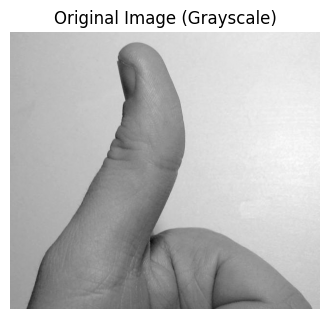

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import urllib.request

# Unduh citra uji jika file lokal belum ada

img = cv2.imread('nyoba.jpg', cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(4, 4))
plt.imshow(img, cmap='gray')
plt.title('Original Image (Grayscale)')
plt.axis('off')
plt.show()

#### b. Simulasi Derau Salt & Pepper

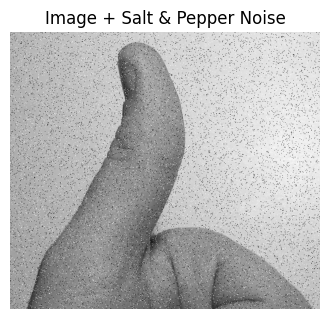

In [4]:
def add_salt_pepper_noise(image, salt_prob=0.02, pepper_prob=0.02):
    noisy = image.copy()
    total_pixels = image.size
    
    # Tambahkan salt (255)
    num_salt = int(salt_prob * total_pixels)
    salt_coords = [np.random.randint(0, d, num_salt) for d in image.shape]
    noisy[salt_coords[0], salt_coords[1]] = 255
    
    # Tambahkan pepper (0)
    num_pepper = int(pepper_prob * total_pixels)
    pepper_coords = [np.random.randint(0, d, num_pepper) for d in image.shape]
    noisy[pepper_coords[0], pepper_coords[1]] = 0
    
    return noisy

noisy_img = add_salt_pepper_noise(img, salt_prob=0.03, pepper_prob=0.03)

plt.figure(figsize=(4, 4))
plt.imshow(noisy_img, cmap='gray')
plt.title('Image + Salt & Pepper Noise')
plt.axis('off')
plt.show()

#### c. Perbandingan: Mean Filter vs Median Filter
Membandingkan respons filter linier (*mean*) dengan filter non-linier (*median*) terhadap derau impulsif.

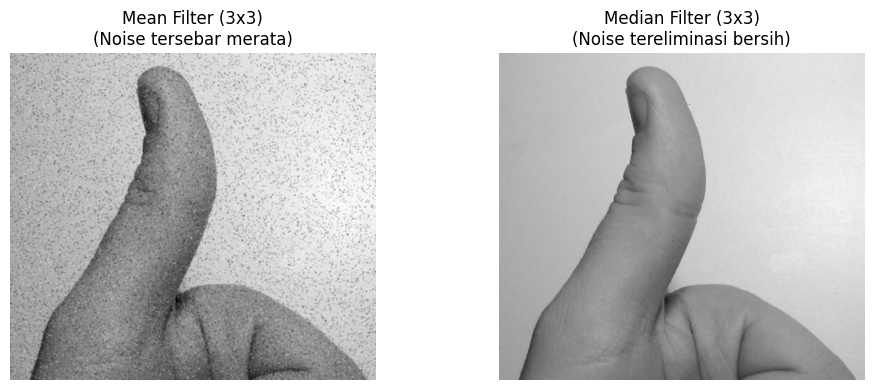

In [5]:
mean_filtered = cv2.blur(noisy_img, (3, 3))
median_filtered = cv2.medianBlur(noisy_img, 3)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(mean_filtered, cmap='gray')
plt.title('Mean Filter (3x3)\n(Noise tersebar merata)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(median_filtered, cmap='gray')
plt.title('Median Filter (3x3)\n(Noise tereliminasi bersih)')
plt.axis('off')

plt.tight_layout()
plt.show()

#### d. Eksperimen Ukuran Kernel Median

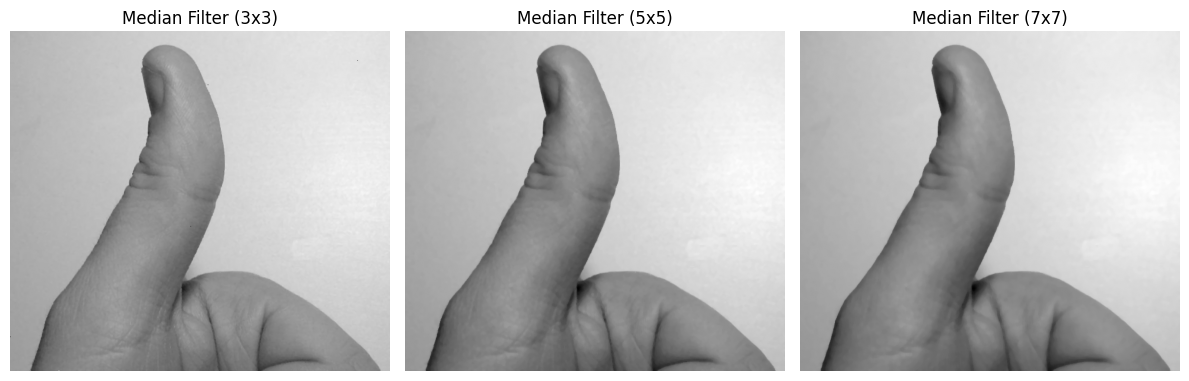

In [6]:
ksizes = [3, 5, 7]

plt.figure(figsize=(12, 4))
for i, k in enumerate(ksizes):
    filtered = cv2.medianBlur(noisy_img, k)
    plt.subplot(1, len(ksizes), i + 1)
    plt.imshow(filtered, cmap='gray')
    plt.title(f'Median Filter ({k}x{k})')
    plt.axis('off')

plt.tight_layout()
plt.show()

### 4. Evaluasi Kuantitatif (PSNR)

Rasio Signal-to-Noise Puncak (*Peak Signal-to-Noise Ratio*) dihitung menggunakan persamaan:

$$
\text{MSE} = \frac{1}{M \times N} \sum_{x=0}^{M-1} \sum_{y=0}^{N-1} [I(x,y) - K(x,y)]^2
$$

$$
\text{PSNR} = 10 \cdot \log_{10}\left(\frac{MAX_I^2}{\text{MSE}}\right) = 20 \cdot \log_{10}\left(\frac{255}{\sqrt{\text{MSE}}}\right)
$$

In [7]:
def calculate_psnr(original, processed):
    mse = np.mean((original.astype(np.float64) - processed.astype(np.float64)) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * np.log10(255.0 / np.sqrt(mse))

print(f"PSNR Citra Terkontaminasi Derau : {calculate_psnr(img, noisy_img):.2f} dB")
print(f"PSNR Hasil Mean Filter (3x3)      : {calculate_psnr(img, mean_filtered):.2f} dB")
print("-" * 45)

for k in ksizes:
    filtered = cv2.medianBlur(noisy_img, k)
    score = calculate_psnr(img, filtered)
    print(f"PSNR Hasil Median Filter ({k}x{k})    : {score:.2f} dB")

PSNR Citra Terkontaminasi Derau : 17.29 dB
PSNR Hasil Mean Filter (3x3)      : 26.24 dB
---------------------------------------------
PSNR Hasil Median Filter (3x3)    : 43.51 dB
PSNR Hasil Median Filter (5x5)    : 41.59 dB
PSNR Hasil Median Filter (7x7)    : 40.05 dB


### 5. Kesimpulan

- **Efektivitas Eliminasi:** Filter median meniadakan derau impulsif (*salt & pepper*) tanpa mendistribusikan nilai ekstrem tersebut ke lingkungan sekitarnya, berbeda dengan filter rata-rata yang membuat noda kabur.
- **Kompromi Ukuran Jendela:** Kernel yang lebih besar ($5 \times 5$, $7 \times 7$) mampu mengatasi kepadatan derau yang lebih tinggi, namun mulai mengikis sudut dan detail halus citra.
- **Validasi Objektif:** Peningkatan skor PSNR membuktikan rekonstruksi citra secara kuantitatif mendekati citra asli sebelum terkena derau.